# The deterministic mineral solver

Most lithology tools hand you a label and keep the reasoning to themselves. This one is a small
system of linear equations you can read, print, and check by hand. At each depth it writes one
equation per logging tool plus a unity constraint, and solves for the volume of each mineral with
non-negative least squares. We run it on a real North Sea chalk, **15/9-14**.

In [1]:
import sys, warnings
from pathlib import Path
import pandas as pd
warnings.filterwarnings("ignore")
REPO = Path.cwd()
while not (REPO / "src" / "petrophys").exists() and REPO != REPO.parent:
    REPO = REPO.parent
sys.path.insert(0, str(REPO / "src"))

from petrophys.io import read_las
from petrophys.workflow import run_dynamic_workflow
well = read_las(REPO / "src" / "petrophys" / "datasets" / "geolink" / "15_9-14.las")
run_dynamic_workflow(well, lithology="carbonate")     # computes VCL, porosity, and the mineral volumes
well.name

'15/9-14'

## The response equations

Each tool reads a volume-weighted average of what is in the rock. With minerals $V_q, V_c, V_d,
V_a$ (quartz, calcite, dolomite, anhydrite), porosity $\phi$, and a pre-computed clay volume
$V_{cl}$ moved to the right-hand side, you get one equation per tool plus a unity constraint:

- **Unity:** $\;V_q + V_c + V_d + V_a + \phi = 1 - V_{cl}$
- **Density:** $\;V_q\rho_q + V_c\rho_c + V_d\rho_d + V_a\rho_a + \phi\,\rho_{fl} = \rho_{\log} - V_{cl}\rho_{cl}$
- **Neutron:** $\;V_q N_q + V_c N_c + V_d N_d + V_a N_a + \phi\,N_{fl} = N_{\log} - V_{cl}N_{cl}$
- **U (= PEF$\,\cdot\rho$):** $\;V_q U_q + V_c U_c + V_d U_d + V_a U_a + \phi\,U_{fl} = U_{\log} - V_{cl}U_{cl}$
- **Sonic:** $\;V_q \Delta t_q + V_c \Delta t_c + V_d \Delta t_d + V_a \Delta t_a + \phi\,\Delta t_{fl} = \Delta t_{\log} - V_{cl}\Delta t_{cl}$

where $U = \mathrm{PEF}\times\rho$ is the volumetric photoelectric cross-section. Stacked, that is a
linear system $A\,\mathbf{x} = \mathbf{b}$:

$$
\underbrace{\begin{bmatrix}
1 & 1 & 1 & 1 & 1 \\
\rho_q & \rho_c & \rho_d & \rho_a & \rho_{fl} \\
N_q & N_c & N_d & N_a & N_{fl} \\
U_q & U_c & U_d & U_a & U_{fl} \\
\Delta t_q & \Delta t_c & \Delta t_d & \Delta t_a & \Delta t_{fl}
\end{bmatrix}}_{A}
\;
\underbrace{\begin{bmatrix} V_q \\ V_c \\ V_d \\ V_a \\ \phi \end{bmatrix}}_{\mathbf{x}}
=
\underbrace{\begin{bmatrix} 1 \\ \rho_{\log} \\ N_{\log} \\ U_{\log} \\ \Delta t_{\log} \end{bmatrix}
- V_{cl}\begin{bmatrix} 1 \\ \rho_{cl} \\ N_{cl} \\ U_{cl} \\ \Delta t_{cl} \end{bmatrix}}_{\mathbf{b}}
$$

Porosity is solved as an unknown (its column carries the fluid end-points), which keeps the mineral
result independent of any assumed matrix. The system is solved with non-negative least squares so a
volume can never come out negative.

## The same system at one depth, with real numbers

`explain_sample` fills that matrix in at a chosen depth: the response matrix `A` (one row per tool,
one column per mineral plus porosity), the right-hand side `b`, and the NNLS solution `x`. Here is a
clean chalk sample at 2887 m, where all four logs are present so every row is there:

In [2]:
from petrophys.interpretation.lithology.multi_mineral_solver import MultiMineralSolver
system = MultiMineralSolver().explain_sample(well, depth=2887.4)
pd.DataFrame(system["A"], index=system["row_labels"], columns=system["columns"]).round(3)

,quartz,calcite,dolomite,anhydrite,porosity
Unity,1.00,1.000,1.000,1.00,1.00
Density (RHOB),2.65,2.710,2.870,2.96,1.00
Neutron (NPHI),-0.02,0.000,0.020,-0.02,1.00
U = PEF·ρ,4.77,13.821,8.897,14.80,0.36
Sonic (DT),55.50,47.600,43.500,50.00,189.00


In [3]:
solution = pd.Series(system["x"], index=system["columns"], name="solved volume (v/v)")
print(f"NNLS residual: {system['residual']:.3f}")
solution.round(3)

NNLS residual: 0.022


quartz       0.018
calcite      0.768
dolomite     0.000
anhydrite    0.000
porosity     0.062
Name: solved volume (v/v), dtype: float64

The solver calls this chalk almost pure calcite. The $U = \mathrm{PEF}\cdot\rho$ row earns its
place here: calcite reads 13.8 and quartz 4.8, while their density and neutron responses sit nearly
on top of each other (2.71 vs 2.65 g/cc, both near zero on neutron). The residual is small, so on
clean rock the five equations are consistent and the fit is tight. The same $U$ row also tells dolomite from anhydrite: their densities differ by under 0.1 g/cc (2.87 vs 2.96), a contrast a little porosity erases, while their $U$ values stand far apart (9.0 vs 14.9).

## Mineral volumes along the well

The library's mineral template stacks the solved volumes cumulatively. The chalk reads as calcite,
passing down into quartz-rich sand, with clay and porosity making up the rest.

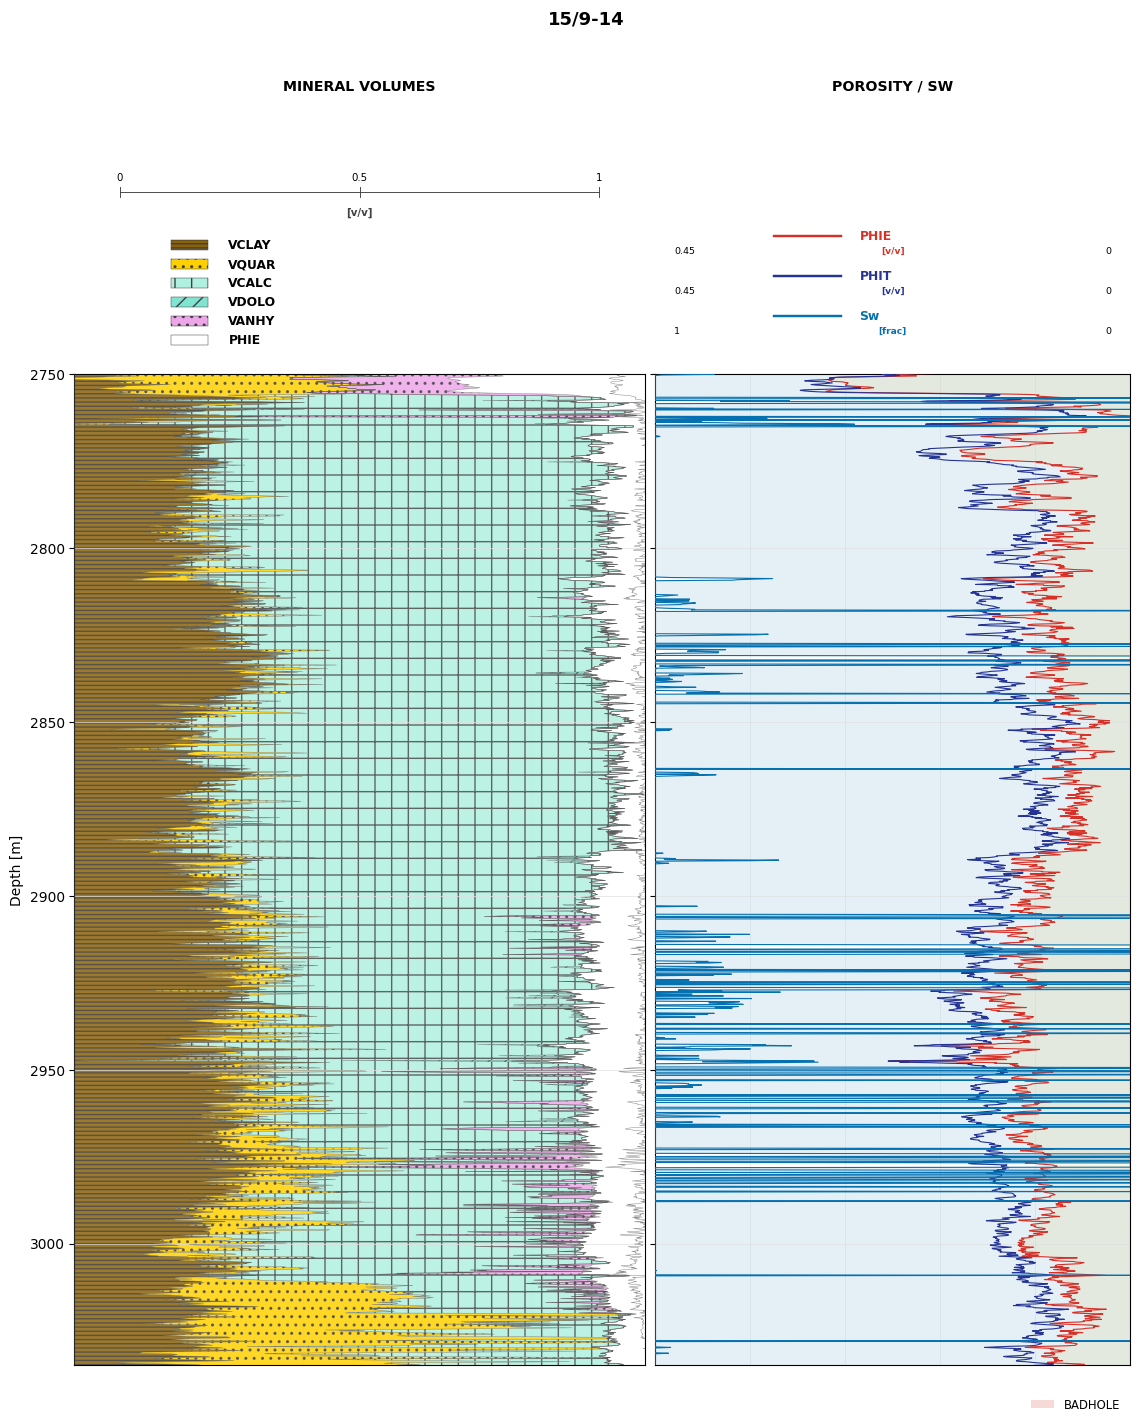

In [4]:
from petrophys.visualization import create_log_viewer
create_log_viewer(well, template_defaults="minerals", depth_range=(2750, 3035));

You never assemble the matrix by hand in practice. `run_dynamic_workflow` writes the mineral
curves and the library plots them. But being able to print `A`, `b`, and `x` at any depth means a
result is never a black box; you can see exactly which equation drove it.

One honest caveat for real data: the photoelectric factor is easily spoiled by barite mud, which is
common offshore and inflates PEF, dragging the carbonate split toward anhydrite. 15/9-14 reads clean
here, but PEF always deserves a look before you trust it, which is why the workflow flags bad hole
and records every decision it makes.